# Neural Network Pruning with Quantum Algorithms — the demo

**One example, end to end:** Fashion-MNIST → pruning choices → learned QUBO → QAOA circuit → real IBM measurements → smaller working network.

This walkthrough uses a completed **16-qubit IBM Fez job**. It is a recorded hardware execution, not a new submission. Cached data lets the presentation run reliably. The optional live CPU retraining cell is off by default.

The only source file you need to read is **pruning.py**. The assets folder contains automatically loaded data and evidence.


In [8]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import pruning as q
arrays, weights, evidence = q.load()
run = evidence['run']


## 1. What does the network do?

An image contains 784 grayscale pixel values. The network predicts one of ten clothing classes.


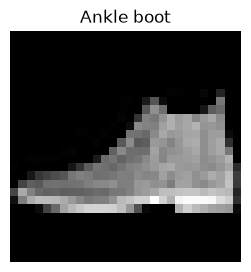

Network: 784 pixels → 32 hidden neurons → 10 clothing-class scores


In [9]:
image_index = 0  # Change this to show another dataset image.
plt.figure(figsize=(3,3))
plt.imshow(arrays['test_images'][image_index], cmap='gray')
plt.title(evidence['class_names'][int(arrays['test_labels'][image_index])])
plt.axis('off'); plt.show()
print('Network: 784 pixels → 32 hidden neurons → 10 clothing-class scores')


## 2. Which neurons can we remove?

The 32 hidden neurons are grouped into 16 pairs. A bit of 1 retains a pair; 0 removes it. Keeping eight pairs leaves 16 hidden neurons. There are 12,870 valid masks.


Selected group mask: [0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0]
Qiskit printed bitstring: 0011101001001110
Valid possibilities: 12870


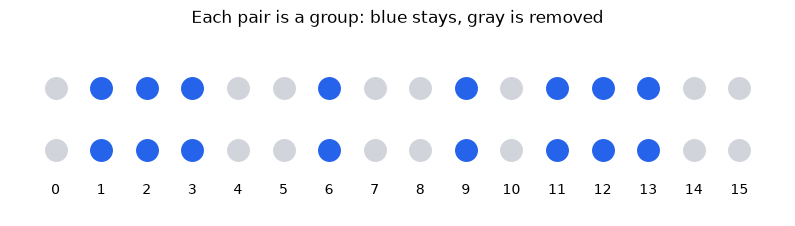

In [10]:
mask = q.mask_from_state(run['selected_state'])
print('Selected group mask:', mask.tolist())
print('Qiskit printed bitstring:', format(run['selected_state'], '016b'))
print('Valid possibilities:', math.comb(q.GROUPS, q.KEEP))
display(q.show_groups())
plt.close('all')


## 3. Approximate the expensive score

The expensive score is validation loss **after restoring the original weights and retraining**. The learned approximation is

$\hat g(m)=c+\sum_i a_i m_i+\sum_{i<j}b_{ij}m_i m_j$.

This run used 192 fit masks. Another 64 disjoint masks audited the approximation during development. The following points are held-out measured losses, not new retraining runs.


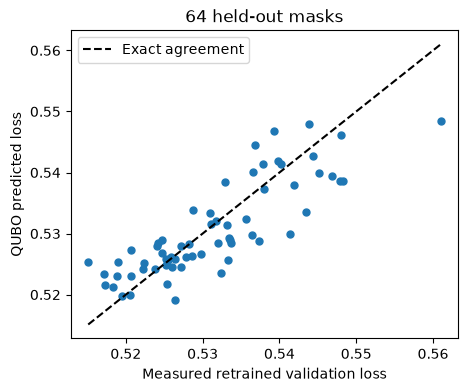

192 fitted examples out of 12870 possible masks.


In [11]:
prediction = q.qubo_scores(arrays['audit_states'])
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(arrays['audit_loss'], prediction, s=25)
limits=[min(arrays['audit_loss'].min(),prediction.min()),max(arrays['audit_loss'].max(),prediction.max())]
ax.plot(limits,limits,'k--',label='Exact agreement')
ax.set(xlabel='Measured retrained validation loss',ylabel='QUBO predicted loss',title='64 held-out masks')
ax.legend(); plt.show()
print('192 fitted examples out of', math.comb(16,8), 'possible masks.')


## 4. Build the actual quantum circuit

The initial Bell pairs prepare valid masks. Cost phases use the QUBO coefficients. Paired RXX/RYY gates form an XY mixer that preserves eight retained groups in an ideal circuit. One layer uses two angles; the saved angles were optimized on a CPU simulator.

The functions `refit_from_saved_labels`, `optimize_angles`, and `build_circuit` in pruning.py show those three steps. Nothing in this notebook submits another IBM job.


Logical qubits: 16
Saved angles [gamma, beta]: [ 1.30754889 -0.42156369]


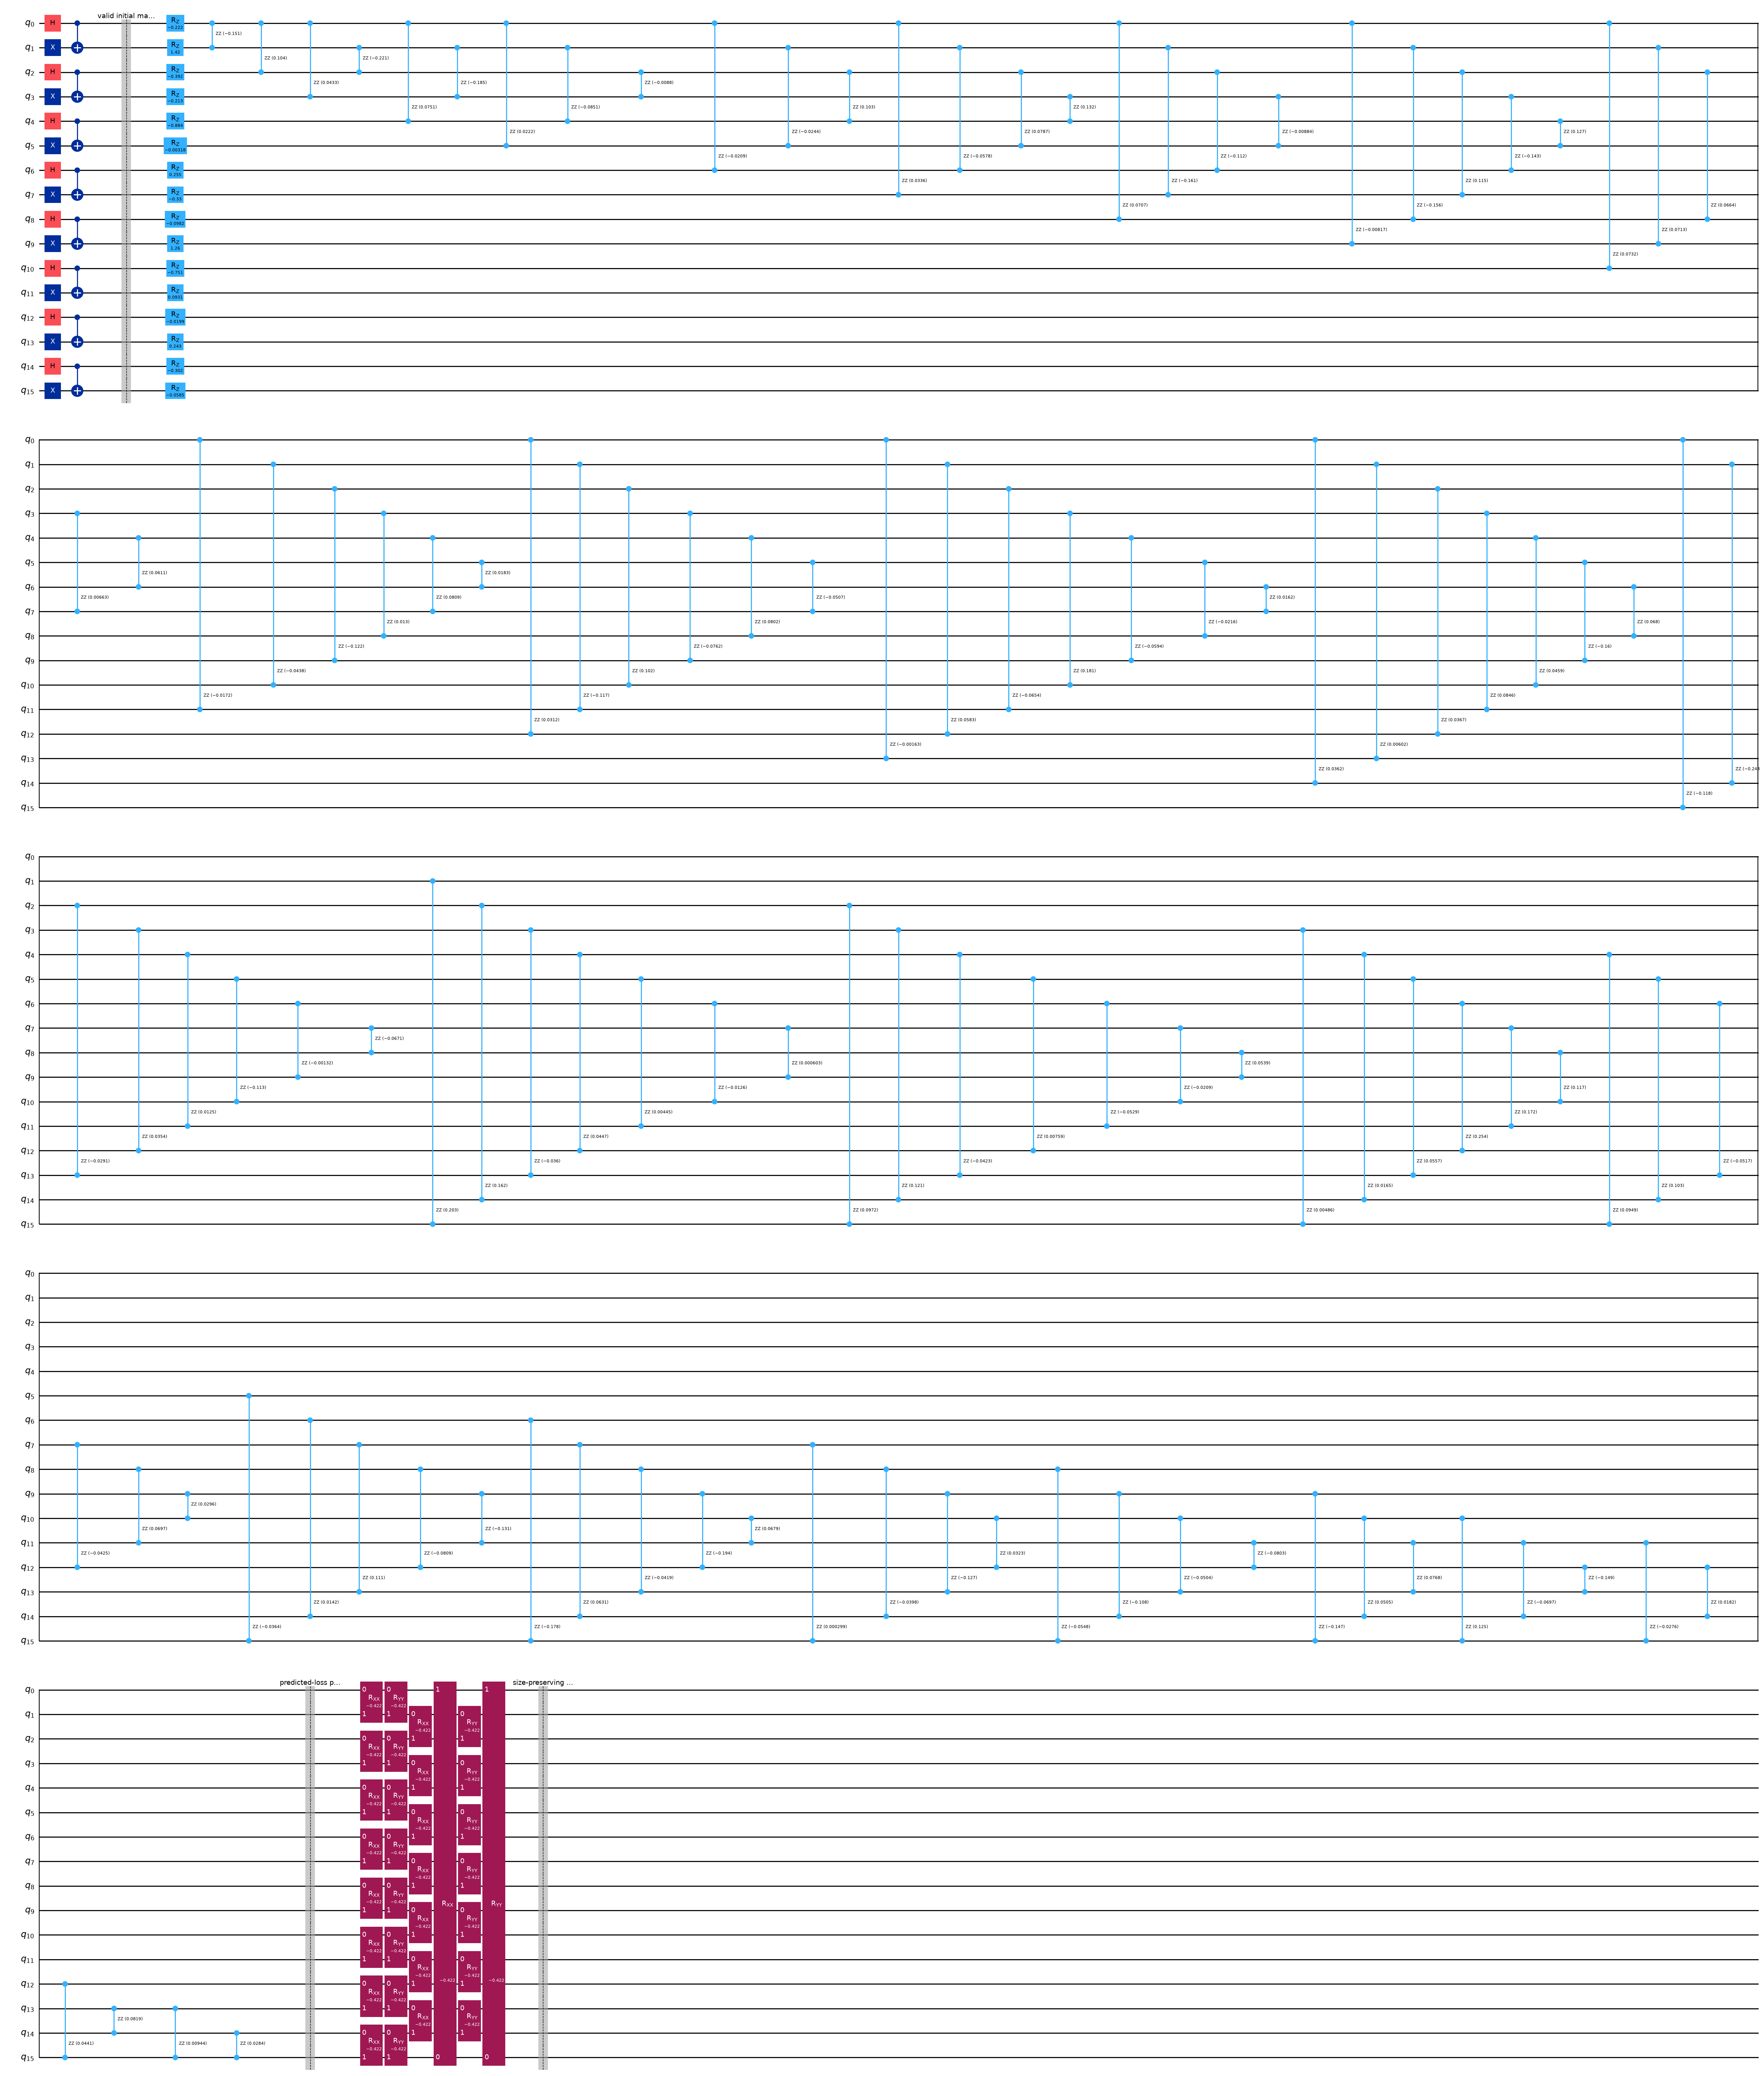

In [12]:
circuit=q.build_circuit()
print('Logical qubits:', circuit.num_qubits)
print('Saved angles [gamma, beta]:', arrays['theta'])
fig=circuit.draw(output='mpl', fold=70)
display(fig); plt.close(fig)


## 5. What came back from IBM?

Each measurement returns one pruning mask. We score feasible observed masks with the QUBO and choose the lowest-scoring one. The most frequent mask need not be the chosen one. Device errors can produce the wrong number of retained groups.


In [13]:
display(pd.DataFrame([{
    'Backend':evidence['hardware']['backend'],
    'IBM job ID':evidence['hardware']['job_id'],
    'Shots':sum(evidence['hardware']['counts'].values()),
    'Reported QPU seconds':run['qpu_reported_seconds'],
    'Whole timed pipeline seconds':round(run['end_to_end_wall_seconds'],1)
}]))
candidates=q.recorded_candidates()
display(candidates.head(8))
assert int(candidates.iloc[0]['state'])==run['selected_state']
print('The selected state was actually observed on the QPU:',format(run['selected_state'],'016b'))
print('Physical-circuit gate counts:',evidence['circuit_metadata']['circuits']['transpiled']['gate_counts'])


,Backend,IBM job ID,Shots,Reported QPU seconds,Whole timed pipeline seconds
0,ibm_fez,dbmjsum74qds73dse56g,4096,3.0,159.0


,mask,state,shots,predicted_loss
0,0011101001001110,14926,1,0.512881
1,0010101001101110,10862,2,0.512890
2,0110101001001110,27214,2,0.513190
3,1000101001101011,35435,2,0.514383
4,0011101000101110,14894,1,0.514431
5,0100101001101110,19054,1,0.514437
6,0111101001000110,31302,1,0.514928
7,0110101001000111,27207,1,0.515138


The selected state was actually observed on the QPU: 0011101001001110
Physical-circuit gate counts: {'sx': 1054, 'rz': 696, 'cz': 469, 'measure': 16, 'x': 8}


## 6. Restore the original initialization, then retrain

Pruning slices out the surviving neurons. Their starting weights are copied from the original untrained network. A fresh optimizer retrains that smaller network.

The first cell verifies initialization restoration without training. The second cell is the optional live demo. Set its flag to True only when you want to retrain on your CPU.


In [7]:
rewound=q.rewind()
neurons=np.flatnonzero(np.repeat(mask,2))
import torch
assert torch.equal(rewound.fc1.weight,weights['initial']['fc1.weight'][neurons])
print('Verified: surviving input weights equal their original initialization.')


Verified: surviving input weights equal their original initialization.


In [7]:
RUN_LIVE_RETRAINING=False
if RUN_LIVE_RETRAINING:
    live_model, live_metrics=q.retrain_selected(epochs=20)
    print('LIVE CPU retraining result:',live_metrics)
else:
    print('Using the already-retrained saved model. No new training performed.')


Using the already-retrained saved model. No new training performed.


## 7. Show the smaller network working

This scorecard is the saved 16-group timed run. The accuracy comparison below can be verified by forward evaluation of its saved weights.


In [9]:
selected=q.saved_model()
metrics=q.evaluate(selected)
assert abs(metrics['accuracy']-run['test_accuracy'])<1e-6
display(pd.DataFrame([
    {'Model':'Dense','Parameters':25450,'Test accuracy (%)':100*evidence['dense']['test_accuracy']},
    {'Model':'QPU-selected subnetwork','Parameters':sum(p.numel() for p in selected.parameters()),'Test accuracy (%)':100*metrics['accuracy']}
]))
with torch.no_grad():
    x=torch.tensor(arrays['test_images'][image_index].reshape(1,784)/255.,dtype=torch.float32)
    predicted=int(selected(x).argmax(1))
print('Prediction for the example:',evidence['class_names'][predicted])
print('Training evaluations: 192 fit masks + 1 final retraining, versus 12,870 candidates in exhaustive retraining.')
print('This is an evaluation-budget comparison; the QUBO approximates actual retraining loss.')


,Model,Parameters,Test accuracy (%)
0,Dense,25450,82.749999
1,QPU-selected subnetwork,12730,82.730001


Prediction for the example: Ankle boot
Training evaluations: 192 fit masks + 1 final retraining, versus 12,870 candidates in exhaustive retraining.
This is an evaluation-budget comparison; the QUBO approximates actual retraining loss.


## Separate result: the eight-group comparison with random pruning

This is a different saved experiment. Its metric is expected accuracy after choosing the best QUBO score from 32 raw proposals, estimated from recorded hardware measurements. It is not the accuracy of the 16-group example above.


In [10]:
r=evidence['separate_8group_random_comparison']
display(pd.DataFrame([
    {'Method':'Eight-group hardware QAOA','Expected best-of-32 accuracy (%)':100*r['quantum_expected_best32_accuracy']},
    {'Method':'Uniform random pruning','Expected best-of-32 accuracy (%)':100*r['random_expected_best32_accuracy']}
]))
print('Hardware improvement:',round(100*(r['quantum_expected_best32_accuracy']-r['random_expected_best32_accuracy']),3),'percentage points')


,Method,Expected best-of-32 accuracy (%)
0,Eight-group hardware QAOA,81.650559
1,Uniform random pruning,81.478237


Hardware improvement: 0.172 percentage points


## What to say at the end

“Neural Network Pruning with Quantum Algorithms links measured retraining performance to a quadratic objective and a real quantum circuit. This saved hardware example retained nearly the same accuracy with half the parameters, using a small fraction of exhaustive retraining's candidate evaluations. A separate eight-group hardware demonstration improved selection accuracy over uniform random pruning.”

The recorded hardware portion makes the demo reliable; the optional CPU cell demonstrates rewinding and retraining live. Older experiments and full evidence are archived outside this demo folder.
